### Visualizações

In [1]:
from pathlib import Path
import mne
import numpy as np
import matplotlib.pyplot as plt

# Caminho dos dados filtrados
DATA_DIR = Path("../../output") if Path("../../output").exists() else Path("./output")
fif_file = DATA_DIR / "eeg_epochs_filtered-epo.fif"

# Caso ainda não tenha executado o pré-processamento, faz fallback para o arquivo bruto
if not fif_file.exists():
    fif_file = DATA_DIR / "eeg_epochs-epo.fif"

# Realizando o carregamento dos dados MNE
epochs = mne.read_epochs(str(fif_file))
print("Epochs carregadas para visualização:")
print(epochs)


Reading /home/andre/Documentos/Git/neural-ca/src/jupyter/../../output/eeg_epochs_filtered-epo.fif ...
Isotrak not found
    Found the data of interest:
        t =       0.00 ...    1998.05 ms
        0 CTF compensation matrices available
Not setting metadata
1151 matching events found
No baseline correction applied
0 projection items activated
Epochs carregadas para visualização:
<EpochsFIF | 1151 events (all good), 0 – 1.998 s (baseline off), ~260.8 MiB, data loaded,
 'eeg': 1151>


In [ ]:
def plots_evoked(evoked_data, color="blue", title=None):
    # Grade de 4 linhas e 2 colunas para os 8 canais
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(evoked_data.ch_names):
        ax = axes[i]

        evoked_chan = evoked_data.copy().pick(picks=[channel_name])
        times = evoked_chan.times
        data = evoked_chan.get_data()
        if data.ndim == 3:
            data = data[0, 0]
        elif data.ndim == 2:
            data = data[0]

        ax.plot(times, data, label=channel_name, color=color)
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        # Rótulo do eixo Y apenas na primeira coluna
        if i % 2 == 0:
            ax.set_ylabel("Amplitude (uV)")
        # Rótulo do eixo X apenas na última linha
        if i >= 6:
            ax.set_xlabel("Tempo (s)")

    if title:
        plt.suptitle(title, y=1.02, fontsize=14)

    plt.tight_layout()
    plt.show()


---
### 2. Visualização de Época Isolada (Cor Azul)
Inspeção detalhada de uma época de atividade neural nos 8 eletrodos selecionados do escalpo.


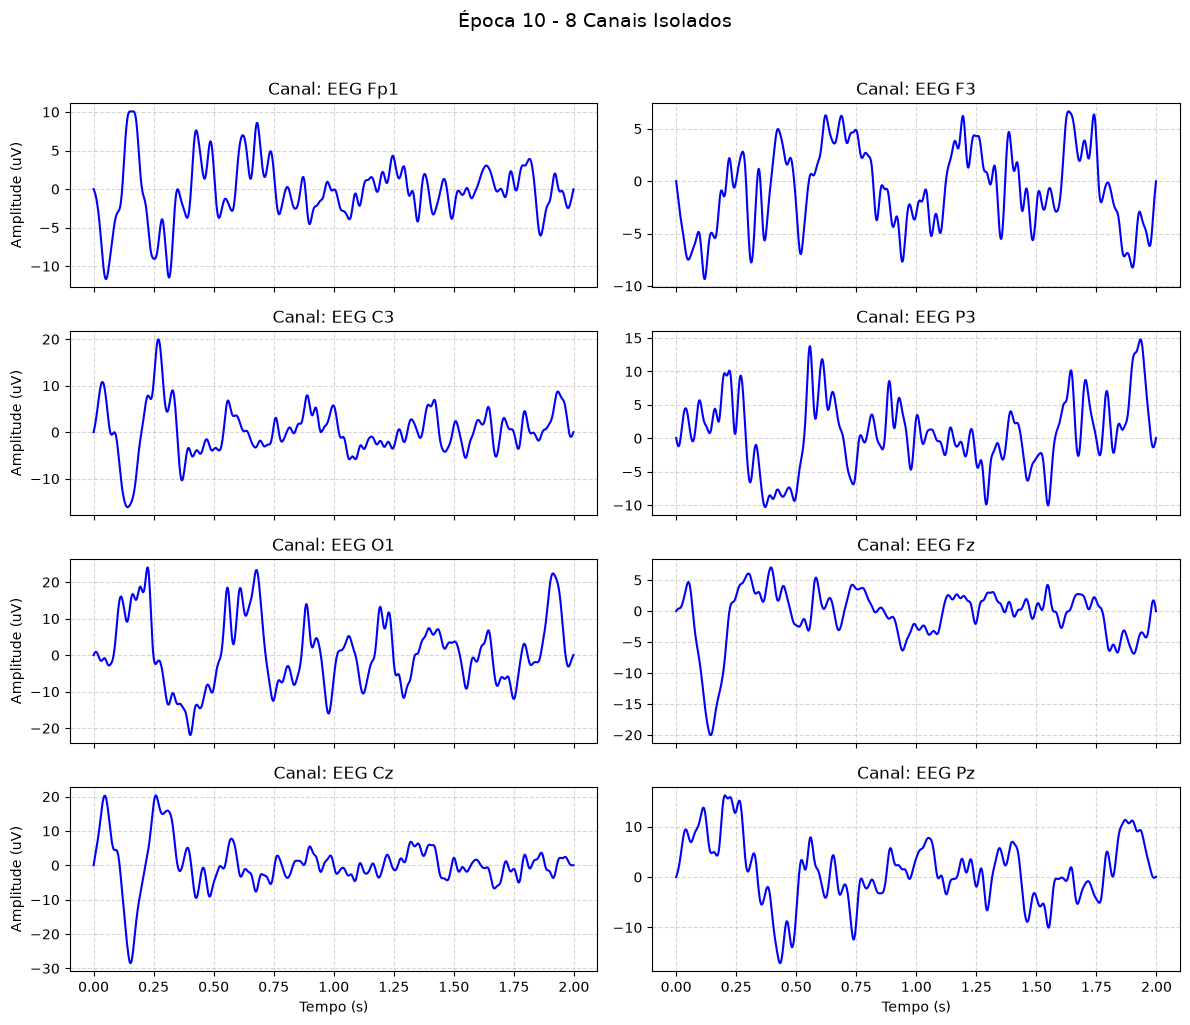

In [3]:
# 8 canais representativos do sistema 10-20
channels_8 = ['EEG Fp1', 'EEG F3', 'EEG C3', 'EEG P3', 'EEG O1', 'EEG Fz', 'EEG Cz', 'EEG Pz']
epochs_8 = epochs.copy().pick(picks=channels_8)

# Plot da Época 10 em azul
epo_idx = 10
plots_evoked(epochs_8[epo_idx], color="blue", title=f"Época {epo_idx} - 8 Canais Isolados")


#### Plot de outro epoch (o 50)

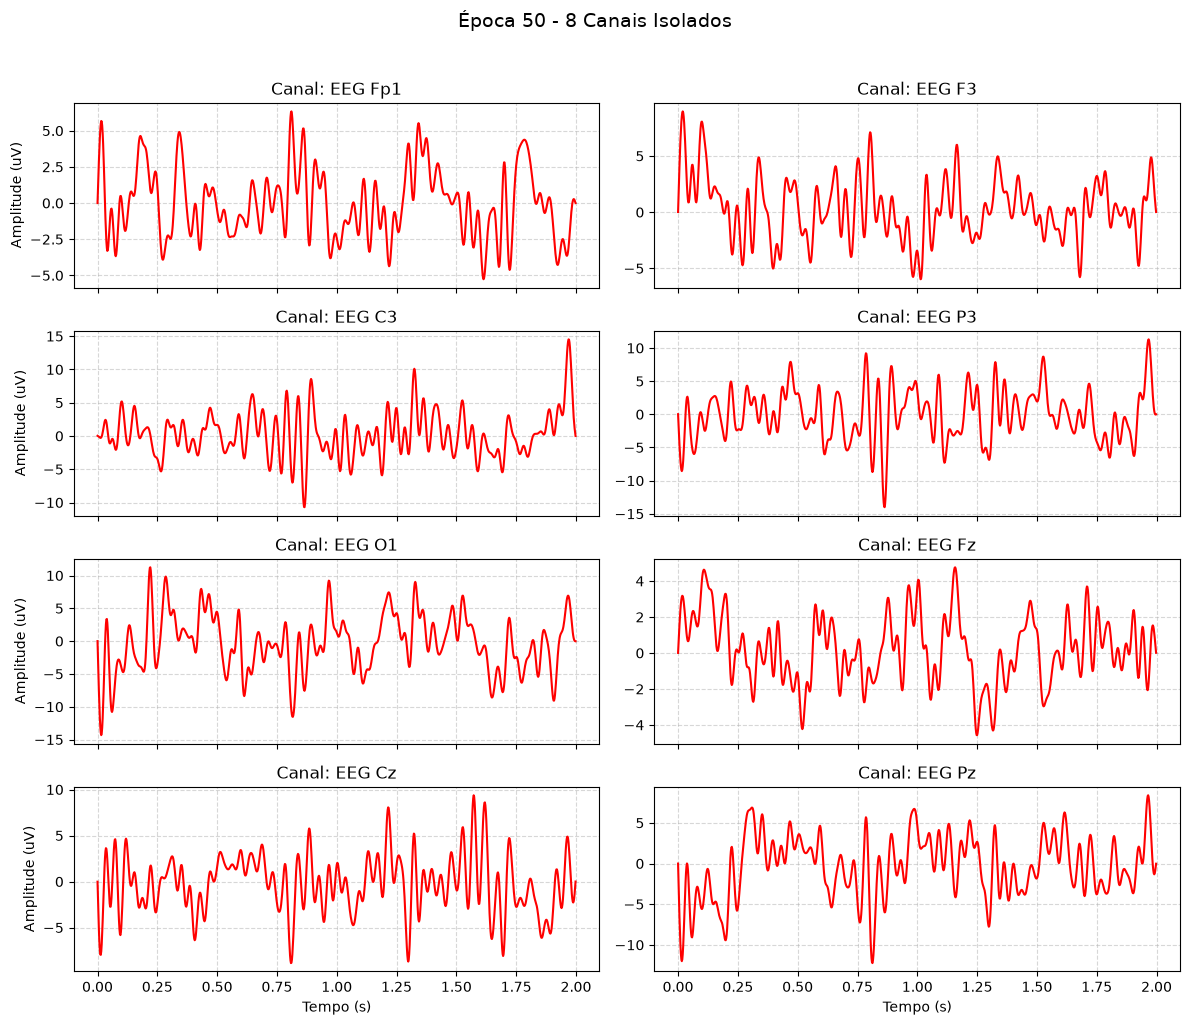

In [4]:
# Plot de outra época para comparação (ex: Época 50 em vermelho)
epo_comp = 50
plots_evoked(epochs_8[epo_comp], color="red", title=f"Época {epo_comp} - 8 Canais Isolados")


---
### 4. Potencial Médio Evocado


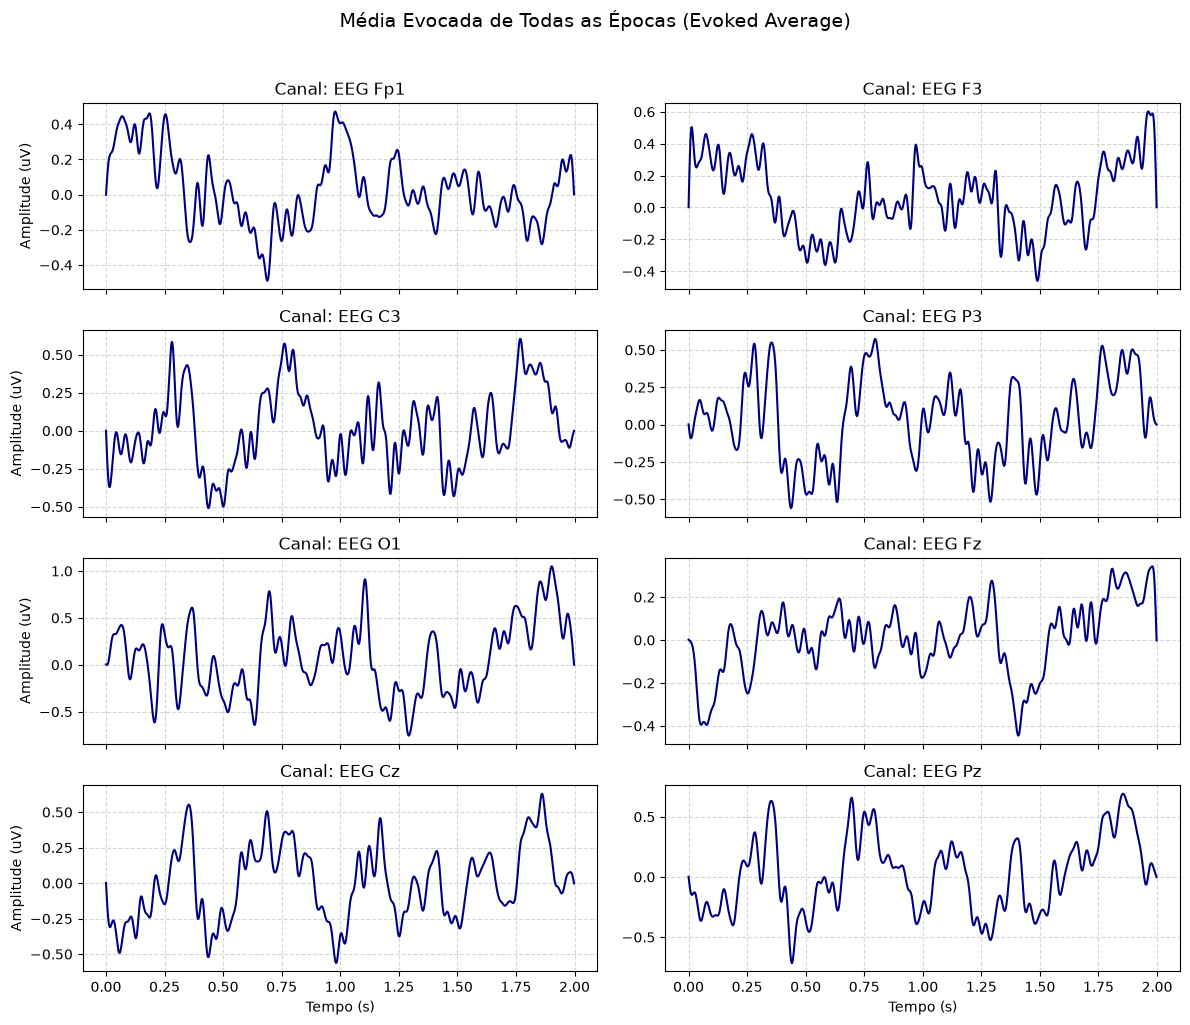

In [5]:
# Média evocada de todas as épocas
evoked_mean = epochs_8.average()
plots_evoked(evoked_mean, color="navy", title="Média Evocada de Todas as Épocas (Evoked Average)")


---
### 5. Todos os canais empilhados

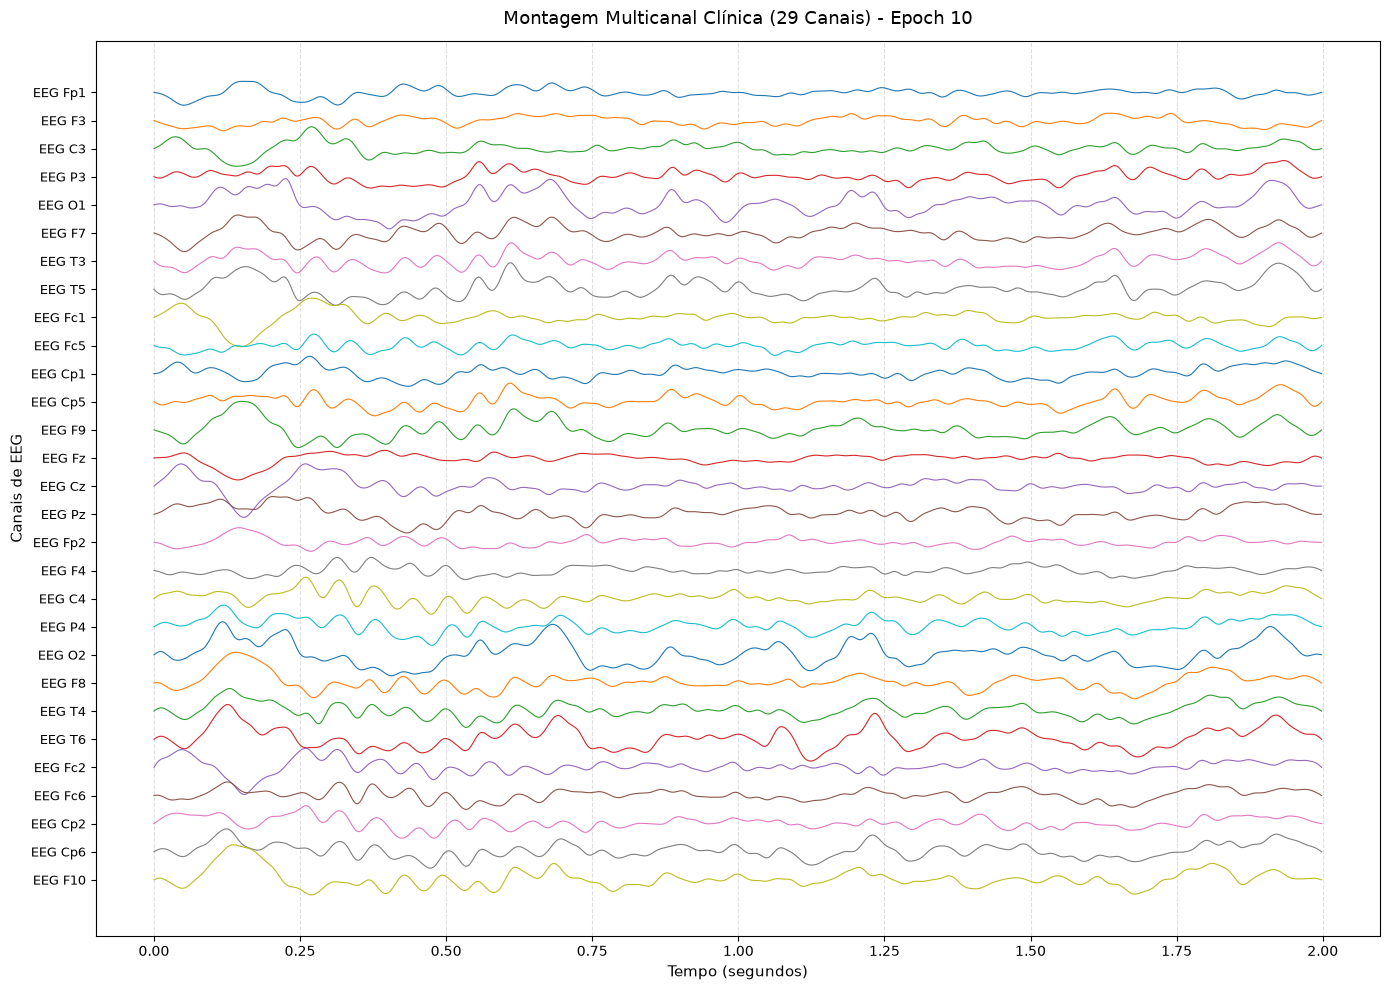

In [6]:
# Montagem clínica completa de todos os 29 canais da Época 10
epoch_to_plot = 10
time_axis = epochs.times
data_all_channels = epochs[epoch_to_plot].get_data()[0]  # shape: (29, 1024)
channel_labels = epochs.ch_names
n_channels = len(channel_labels)

fig, ax = plt.subplots(figsize=(14, 10))

# Espaçamento dinâmico baseado no desvio padrão dos sinais
spacing = np.std(data_all_channels) * 4
if spacing == 0:
    spacing = 50.0

offsets = np.arange(n_channels)[::-1] * spacing

for i, label in enumerate(channel_labels):
    ax.plot(time_axis, data_all_channels[i] + offsets[i], linewidth=0.8)

ax.set_yticks(offsets)
ax.set_yticklabels(channel_labels, fontsize=9)
ax.set_xlabel("Tempo (segundos)", fontsize=11)
ax.set_ylabel("Canais de EEG", fontsize=11)
ax.set_title(f"Montagem Multicanal Clínica (29 Canais) - Epoch {epoch_to_plot}", fontsize=13, pad=12)
ax.grid(True, linestyle="--", alpha=0.4, axis="x")
plt.tight_layout()
plt.show()
